# dataAnalysis — cortes UNet 2D (MRI ↔ SPECT)

Visualización del rango axial usado en `fst_clsfeat_mnet2d_arad` y de la relación emparejada MRI/SPECT (mismos sujetos, mismos índices Z).

- Rango config: `slice_range = [-1, 15]` → índices de vóxel **0…15** (el −1 se recorta a 0)
- Eje: axial (`axis=2`)
- Preprocess: MRI z-score±3σ→[0,1]; SPECT p1–p99→[0,1]
- Tiles CNN: 256×256 RGB float `[0,1]`


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd

FST_ROOT = Path("/workspace/IL-FST")
sys.path.insert(0, str(FST_ROOT))

from fst.slice_data import (
    DEFAULT_SLICE_AXIS,
    DEFAULT_SLICE_RANGE,
    DEFAULT_TILE_SIZE,
    PREPROCESS_SPECS,
    load_id_list,
    load_labels,
    map_volume_to_unit_interval,
    slice_indices,
    slice_to_rgb,
)

MRI_ROOT = Path("/workspace/IL-CLDM/data_rois/whole_MRI")
SPECT_ROOT = Path("/workspace/IL-CLDM/data_rois/whole_Abeta_4mm")
META_CSV = Path("/workspace/IL-CLDM/data_info/data_info.csv")
TRAIN_LIST = Path("/workspace/IL-CLDM/data_info/train.txt")
TEST_LIST = Path("/workspace/IL-CLDM/data_info/test.txt")
EXP_DIR = FST_ROOT / "result" / "fst_clsfeat_mnet2d_arad"

Z_MIN, Z_MAX = DEFAULT_SLICE_RANGE
LABEL_NAME = {0: "control", 1: "PD"}

print("slice_range config:", (Z_MIN, Z_MAX))
print("preprocess:", PREPROCESS_SPECS)
print("tile_size:", DEFAULT_TILE_SIZE)


slice_range config: (-1, 15)
preprocess: {'mri': 'volume_zscore_clip3sigma_to_unit', 'spect': 'volume_p1_p99_to_unit_no_zscore'}
tile_size: (256, 256)


## 1. Inventario de sujetos y emparejamiento MRI/SPECT

Cada ID debe existir en **ambos** roots ROI 4 mm. El UNet 2D entrena con pares `(MRI_tile_z, SPECT_tile_z)` del mismo sujeto y mismo `slice_idx`.


In [2]:
labels = load_labels(META_CSV)
meta = pd.read_csv(META_CSV)
meta["ID"] = meta["ID"].astype(str)

train_ids = load_id_list(TRAIN_LIST)
test_ids = load_id_list(TEST_LIST)
all_ids = sorted(set(train_ids) | set(test_ids), key=lambda x: int(x) if x.isdigit() else x)


def has_pair(sid: str) -> bool:
    return (MRI_ROOT / f"{sid}.nii.gz").is_file() and (SPECT_ROOT / f"{sid}.nii.gz").is_file()


rows = []
for sid in all_ids:
    rows.append({
        "subject_id": sid,
        "label": int(labels.get(sid, -1)),
        "label_name": LABEL_NAME.get(int(labels.get(sid, -1)), "?"),
        "split_meta": meta.loc[meta["ID"] == sid, "split"].iloc[0] if (meta["ID"] == sid).any() else "?",
        "in_train_list": sid in train_ids,
        "in_test_list": sid in test_ids,
        "mri_exists": (MRI_ROOT / f"{sid}.nii.gz").is_file(),
        "spect_exists": (SPECT_ROOT / f"{sid}.nii.gz").is_file(),
        "paired": has_pair(sid),
    })

inv = pd.DataFrame(rows)
print("sujetos listados:", len(inv))
print("pares MRI+SPECT:", int(inv["paired"].sum()))
print("solo MRI:", int((inv["mri_exists"] & ~inv["spect_exists"]).sum()))
print("solo SPECT:", int((inv["spect_exists"] & ~inv["mri_exists"]).sum()))
print()
print("por split (meta) × label:")
display(pd.crosstab(inv["split_meta"], inv["label_name"], margins=True))
print()
print("train.txt / test.txt × label (solo pares):")
paired = inv[inv["paired"]].copy()
paired["list_split"] = np.where(
    paired["in_test_list"], "test", np.where(paired["in_train_list"], "train", "other")
)
display(pd.crosstab(paired["list_split"], paired["label_name"], margins=True))

fit_path, val_path = EXP_DIR / "train_fit.txt", EXP_DIR / "val_holdout.txt"
if fit_path.exists() and val_path.exists():
    fit_ids = set(load_id_list(fit_path))
    val_ids = set(load_id_list(val_path))
    print(f"\nExperimento {EXP_DIR.name}: fit={len(fit_ids)} val_holdout={len(val_ids)}")
    for k in (0, 1):
        n = sum(1 for x in val_ids if int(labels[x]) == k)
        print(f"  val holdout {LABEL_NAME[k]}: {n}")


sujetos listados: 181
pares MRI+SPECT: 181
solo MRI: 0
solo SPECT: 0

por split (meta) × label:


label_name,PD,control,All
split_meta,,,
test,20,14,34
train,89,58,147
All,109,72,181



train.txt / test.txt × label (solo pares):


label_name,PD,control,All
list_split,,,
test,20,14,34
train,89,58,147
All,109,72,181



Experimento fst_clsfeat_mnet2d_arad: fit=132 val_holdout=15
  val holdout control: 6
  val holdout PD: 9


## 2. Forma de volúmenes y cortes efectivos en Z

Con `slice_range=(-1, 15)` y `slice_indices`, el −1 se clipea a 0 → **16 cortes** (0…15) si la profundidad ≥ 16.


In [3]:
sample_ids = [s for s in train_ids if has_pair(s)][:5]
shape_rows = []
for sid in sample_ids:
    mri = nib.load(str(MRI_ROOT / f"{sid}.nii.gz"))
    spect = nib.load(str(SPECT_ROOT / f"{sid}.nii.gz"))
    mshape = mri.shape
    sshape = spect.shape
    zs_m = slice_indices(Z_MIN, Z_MAX, mshape, DEFAULT_SLICE_AXIS)
    zs_s = slice_indices(Z_MIN, Z_MAX, sshape, DEFAULT_SLICE_AXIS)
    shape_rows.append({
        "subject_id": sid,
        "mri_shape": mshape,
        "spect_shape": sshape,
        "shapes_equal": mshape == sshape,
        "n_z_mri": len(zs_m),
        "n_z_spect": len(zs_s),
        "z_indices": zs_m,
        "affine_diag_mri": np.round(np.diag(mri.affine)[:3], 3).tolist(),
        "affine_diag_spect": np.round(np.diag(spect.affine)[:3], 3).tolist(),
    })

shapes_df = pd.DataFrame(shape_rows)
display(shapes_df)
assert all(shapes_df["shapes_equal"]), "MRI/SPECT shapes differ for some subjects"
print("cortes usados (ejemplo):", shapes_df.iloc[0]["z_indices"])


,subject_id,mri_shape,spect_shape,shapes_equal,n_z_mri,n_z_spect,z_indices,affine_diag_mri,affine_diag_spect
0,3102,"(96, 112, 114)","(96, 112, 114)",True,16,16,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[-1.0, 1.0, 1.0]","[-1.0, 1.0, 1.0]"
1,3104,"(96, 112, 114)","(96, 112, 114)",True,16,16,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[-1.0, 1.0, 1.0]","[-1.0, 1.0, 1.0]"
2,3105,"(96, 112, 114)","(96, 112, 114)",True,16,16,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[-1.0, 1.0, 1.0]","[-1.0, 1.0, 1.0]"
3,3106,"(96, 112, 114)","(96, 112, 114)",True,16,16,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[-1.0, 1.0, 1.0]","[-1.0, 1.0, 1.0]"
4,3111,"(96, 112, 114)","(96, 112, 114)",True,16,16,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...","[-1.0, 1.0, 1.0]","[-1.0, 1.0, 1.0]"


cortes usados (ejemplo): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


## 3. Visualización de los 16 cortes: MRI | SPECT (mismo Z)

Elige un sujeto. Izquierda = MRI preprocesada (unit); derecha = SPECT preprocesada (unit).


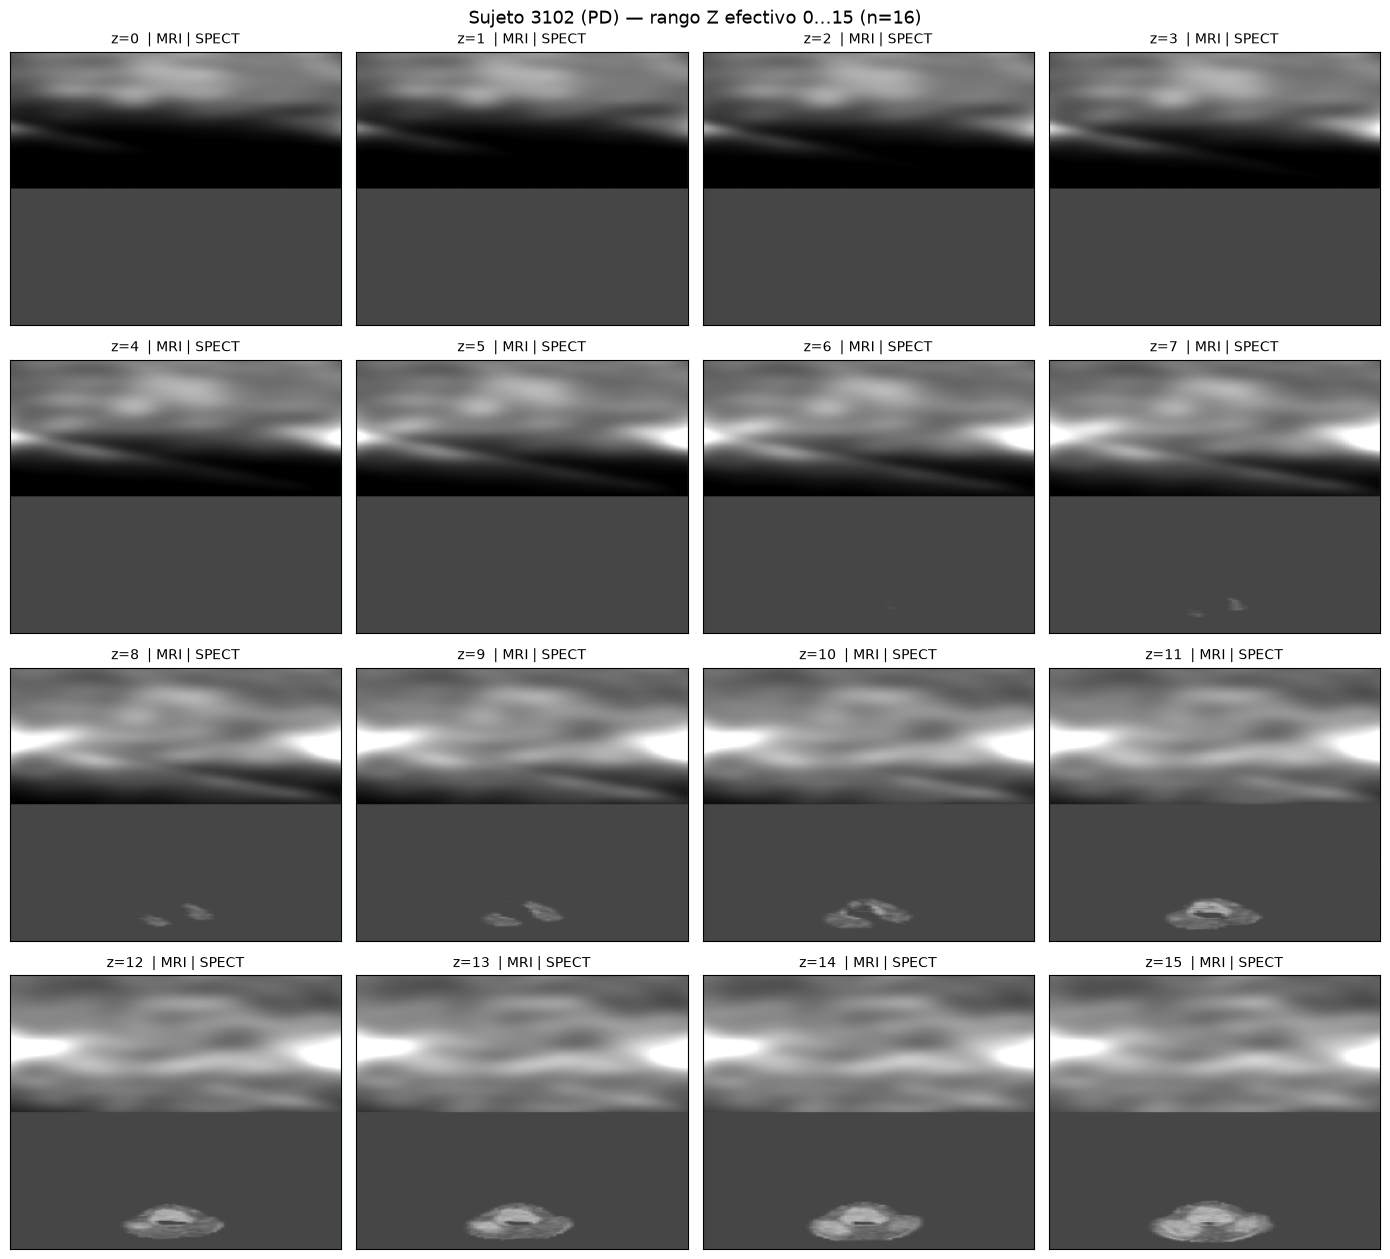

In [4]:
SUBJECT_ID = "3102"  # cambiar libremente
assert has_pair(SUBJECT_ID), f"missing pair for {SUBJECT_ID}"

mri_raw = np.asarray(nib.load(str(MRI_ROOT / f"{SUBJECT_ID}.nii.gz")).get_fdata(), dtype=np.float32)
spect_raw = np.asarray(nib.load(str(SPECT_ROOT / f"{SUBJECT_ID}.nii.gz")).get_fdata(), dtype=np.float32)
mri_u = map_volume_to_unit_interval(mri_raw, "mri")
spect_u = map_volume_to_unit_interval(spect_raw, "spect")
zs = slice_indices(Z_MIN, Z_MAX, mri_u.shape, DEFAULT_SLICE_AXIS)
ylab = LABEL_NAME.get(int(labels[SUBJECT_ID]), "?")

n = len(zs)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows))
axes = np.atleast_2d(axes)

for i, z in enumerate(zs):
    r, c = divmod(i, ncols)
    ax = axes[r, c]
    msl = mri_u[:, :, z]
    ssl = spect_u[:, :, z]
    canvas = np.concatenate([msl, ssl], axis=1)
    ax.imshow(canvas.T, origin="lower", cmap="gray", vmin=0, vmax=1, aspect="auto")
    ax.axvline(msl.shape[0] - 0.5, color="cyan", lw=0.8)
    ax.set_title(f"z={z}  | MRI | SPECT", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

for j in range(n, nrows * ncols):
    r, c = divmod(j, ncols)
    axes[r, c].axis("off")

fig.suptitle(
    f"Sujeto {SUBJECT_ID} ({ylab}) — rango Z efectivo {zs[0]}…{zs[-1]} (n={n})",
    fontsize=13,
)
fig.tight_layout()
plt.show()


## 4. Tiles 256×256 como entran a MobileNet / UNet 2D

Misma normalización de volumen + resize bilineal a 256×256 (canal RGB repetido).


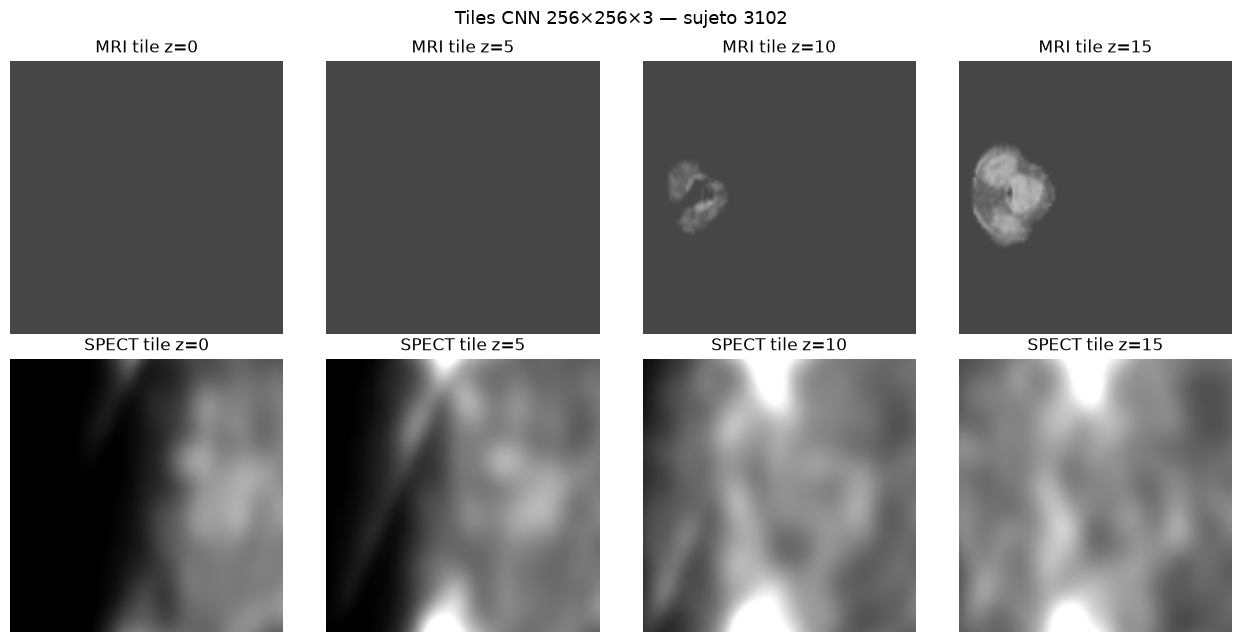

tile dtype/shape/range MRI: float32 (256, 256, 3) 0.27450981736183167 0.7450980544090271
tile dtype/shape/range SPECT: float32 (256, 256, 3) 0.29411765933036804 1.0


In [5]:
show_z = [zs[0], zs[len(zs) // 3], zs[2 * len(zs) // 3], zs[-1]]
fig, axes = plt.subplots(2, len(show_z), figsize=(3.2 * len(show_z), 6.5))

for j, z in enumerate(show_z):
    m_tile = slice_to_rgb(mri_u[:, :, z])
    s_tile = slice_to_rgb(spect_u[:, :, z])
    axes[0, j].imshow(m_tile)
    axes[0, j].set_title(f"MRI tile z={z}")
    axes[0, j].axis("off")
    axes[1, j].imshow(s_tile)
    axes[1, j].set_title(f"SPECT tile z={z}")
    axes[1, j].axis("off")

fig.suptitle(f"Tiles CNN 256×256×3 — sujeto {SUBJECT_ID}", fontsize=13)
fig.tight_layout()
plt.show()

print("tile dtype/shape/range MRI:", m_tile.dtype, m_tile.shape, float(m_tile.min()), float(m_tile.max()))
print("tile dtype/shape/range SPECT:", s_tile.dtype, s_tile.shape, float(s_tile.min()), float(s_tile.max()))


## 5. Relación cuantitativa MRI ↔ SPECT en el rango Z

Por corte: intensidad media, fracción de vóxeles > 0.1, y correlación espacial flatten MRI–SPECT (misma grilla ROI).


,z,mri_mean,spect_mean,mri_frac>0.1,spect_frac>0.1,corr_mri_spect
0,0,0.2760,0.2362,1.0,0.5577,NaN
1,1,0.2760,0.2485,1.0,0.5895,NaN
2,2,0.2760,0.2708,1.0,0.6332,NaN
3,3,0.2760,0.2999,1.0,0.6840,NaN
4,4,0.2760,0.3325,1.0,0.7347,NaN
5,5,0.2760,0.3664,1.0,0.7910,NaN
6,6,0.2760,0.3999,1.0,0.8490,-0.0280
7,7,0.2764,0.4316,1.0,0.9084,-0.0633
8,8,0.2773,0.4604,1.0,0.9579,-0.0863
9,9,0.2784,0.4854,1.0,0.9856,-0.0873


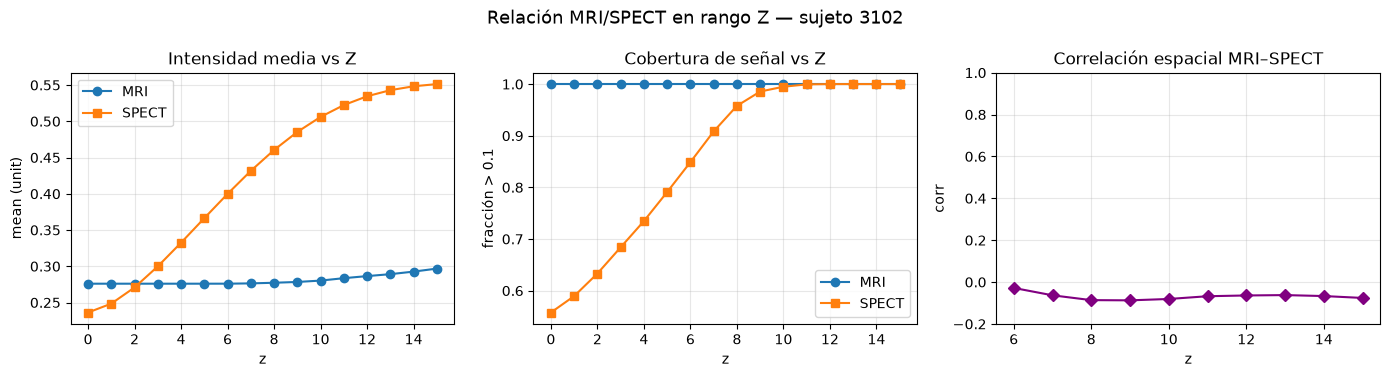

In [6]:
def slice_stats(vol_u: np.ndarray, z: int) -> dict:
    sl = vol_u[:, :, z]
    return {
        "mean": float(sl.mean()),
        "std": float(sl.std()),
        "frac_gt_0.1": float((sl > 0.1).mean()),
        "p50": float(np.percentile(sl, 50)),
        "p95": float(np.percentile(sl, 95)),
    }


stat_rows = []
for z in zs:
    sm = slice_stats(mri_u, z)
    ss = slice_stats(spect_u, z)
    mflat = mri_u[:, :, z].ravel()
    sflat = spect_u[:, :, z].ravel()
    if mflat.std() > 1e-8 and sflat.std() > 1e-8:
        corr = float(np.corrcoef(mflat, sflat)[0, 1])
    else:
        corr = float("nan")
    stat_rows.append({
        "z": z,
        "mri_mean": sm["mean"],
        "spect_mean": ss["mean"],
        "mri_frac>0.1": sm["frac_gt_0.1"],
        "spect_frac>0.1": ss["frac_gt_0.1"],
        "corr_mri_spect": corr,
    })

stats_df = pd.DataFrame(stat_rows)
display(stats_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(stats_df["z"], stats_df["mri_mean"], "o-", label="MRI")
axes[0].plot(stats_df["z"], stats_df["spect_mean"], "s-", label="SPECT")
axes[0].set_xlabel("z")
axes[0].set_ylabel("mean (unit)")
axes[0].legend()
axes[0].set_title("Intensidad media vs Z")
axes[0].grid(True, alpha=0.3)

axes[1].plot(stats_df["z"], stats_df["mri_frac>0.1"], "o-", label="MRI")
axes[1].plot(stats_df["z"], stats_df["spect_frac>0.1"], "s-", label="SPECT")
axes[1].set_xlabel("z")
axes[1].set_ylabel("fracción > 0.1")
axes[1].legend()
axes[1].set_title("Cobertura de señal vs Z")
axes[1].grid(True, alpha=0.3)

axes[2].plot(stats_df["z"], stats_df["corr_mri_spect"], "D-", color="purple")
axes[2].set_xlabel("z")
axes[2].set_ylabel("corr")
axes[2].set_title("Correlación espacial MRI–SPECT")
axes[2].set_ylim(-0.2, 1.0)
axes[2].grid(True, alpha=0.3)

fig.suptitle(f"Relación MRI/SPECT en rango Z — sujeto {SUBJECT_ID}", fontsize=13)
fig.tight_layout()
plt.show()


## 6. Galería multi-sujeto (corte medio del rango)

Comparación rápida de la relación anatómica/funcional en el corte central del band Z.


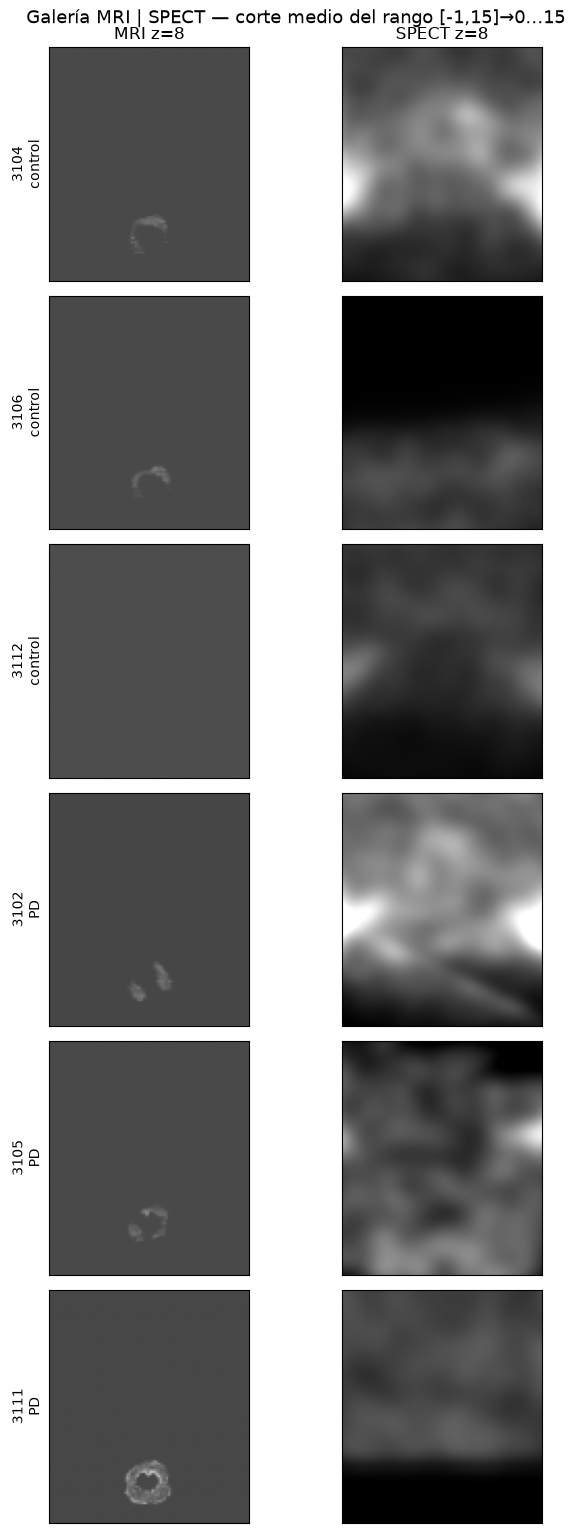

In [7]:
gallery_ids = [s for s in train_ids if has_pair(s)][:8]
ctrl = [s for s in gallery_ids if int(labels[s]) == 0][:3]
pd_ids = [s for s in gallery_ids if int(labels[s]) == 1][:3]
gallery_ids = (ctrl + pd_ids) or gallery_ids

fig, axes = plt.subplots(len(gallery_ids), 2, figsize=(7, 2.6 * len(gallery_ids)))
if len(gallery_ids) == 1:
    axes = np.array([axes])

for i, sid in enumerate(gallery_ids):
    mr = map_volume_to_unit_interval(
        np.asarray(nib.load(str(MRI_ROOT / f"{sid}.nii.gz")).get_fdata(), dtype=np.float32), "mri"
    )
    sp = map_volume_to_unit_interval(
        np.asarray(nib.load(str(SPECT_ROOT / f"{sid}.nii.gz")).get_fdata(), dtype=np.float32), "spect"
    )
    zz = slice_indices(Z_MIN, Z_MAX, mr.shape, DEFAULT_SLICE_AXIS)
    z_mid = zz[len(zz) // 2]
    axes[i, 0].imshow(mr[:, :, z_mid].T, origin="lower", cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_ylabel(f"{sid}\n{LABEL_NAME[int(labels[sid])]}", fontsize=10)
    axes[i, 0].set_title(f"MRI z={z_mid}" if i == 0 else "")
    axes[i, 0].set_xticks([])
    axes[i, 0].set_yticks([])
    axes[i, 1].imshow(sp[:, :, z_mid].T, origin="lower", cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"SPECT z={z_mid}" if i == 0 else "")
    axes[i, 1].set_xticks([])
    axes[i, 1].set_yticks([])

fig.suptitle("Galería MRI | SPECT — corte medio del rango [-1,15]→0…15", fontsize=13)
fig.tight_layout()
plt.show()


## 7. Resumen de la relación de datos

| Aspecto | Detalle |
|---------|---------|
| Emparejamiento | 1:1 por `subject_id` |
| Cortes | mismos `slice_idx` Z ∈ [0, 15] (16 por sujeto) |
| Espacio | ROI 4 mm, shape típica ~96×112×114 |
| Entrada UNet 2D | features MobileNet `conv_pw_13_relu` (8×8×1024) de cada tile |
| Supervisión MSE | `f_hat(MRI) ↔ f_spect(SPECT)` en el mismo z |
| Supervisión CE | cabeza SPECT sobre `f_hat` + label del sujeto |

Cambiar `SUBJECT_ID` en la sección 3 para explorar otros casos.


## 8. Visor interactivo Z (índices nibabel / código)

Usa este panel para **elegir el rango axial real** que debe entrar al UNet 2D.

- El índice `z` es el de **nibabel / NumPy** (`volume[:, :, z]`), **0-based** (aquí ~`0…113`, no el de MRIcroGL).
- Si la celda se queda en *Running…* sin figura: **Stop** esa celda y vuelve a ejecutar la del slider (o usa el fallback sin widgets).
- `continuous_update=False`: la figura se actualiza al **soltar** el slider.
- Opcional: `FLIP_Z = True` si el orden superior↔inferior te cuadra más con MRIcroGL.


In [ ]:
# Si la celda anterior quedó "Running…", interrúmpela (Stop) y ejecuta ESTA.
# El hang venía de interactive_output + matplotlib dentro de un Output widget.

%matplotlib inline
from ipywidgets import interact, IntSlider

# --- elige sujeto ---
VIZ_SUBJECT = "3102"
FLIP_Z = False  # True ≈ eje invertido tipo MRIcroGL

assert has_pair(VIZ_SUBJECT), f"missing MRI/SPECT pair for {VIZ_SUBJECT}"

viz_mri = map_volume_to_unit_interval(
    np.asarray(nib.load(str(MRI_ROOT / f"{VIZ_SUBJECT}.nii.gz")).get_fdata(), dtype=np.float32),
    "mri",
)
viz_spect = map_volume_to_unit_interval(
    np.asarray(nib.load(str(SPECT_ROOT / f"{VIZ_SUBJECT}.nii.gz")).get_fdata(), dtype=np.float32),
    "spect",
)
nz = int(viz_mri.shape[DEFAULT_SLICE_AXIS])
current_zs = slice_indices(Z_MIN, Z_MAX, viz_mri.shape, DEFAULT_SLICE_AXIS)
ylab = LABEL_NAME.get(int(labels[VIZ_SUBJECT]), "?")
print(f"sujeto={VIZ_SUBJECT} ({ylab}) shape={viz_mri.shape}  z∈[0,{nz-1}]")
print(f"rango actual experimento: {current_zs[0]}…{current_zs[-1]} (n={len(current_zs)})")


def show_slice(z):
    zi = (nz - 1 - z) if FLIP_Z else z
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    axes[0].imshow(viz_mri[:, :, zi].T, origin="lower", cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(f"MRI  z={zi}")
    axes[0].axis("off")
    axes[1].imshow(viz_spect[:, :, zi].T, origin="lower", cmap="gray", vmin=0, vmax=1)
    axes[1].set_title(f"SPECT  z={zi}")
    axes[1].axis("off")
    tag = "EN rango actual" if current_zs[0] <= zi <= current_zs[-1] else "fuera rango actual"
    fig.suptitle(f"{VIZ_SUBJECT} | array_z={zi}/{nz-1}  ({tag})", fontsize=12)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


# continuous_update=False: solo redibuja al soltar el slider (evita cuelgues)
interact(show_slice, z=IntSlider(min=0, max=nz - 1, step=1, value=nz // 2, continuous_update=False))


sujeto=3102 (PD) shape=(96, 112, 114)  z∈[0,113]
rango actual experimento: 0…15 (n=16)


interactive(children=(IntSlider(value=57, continuous_update=False, description='z', max=113), Output()), _dom_…

<function __main__.show_slice(z)>

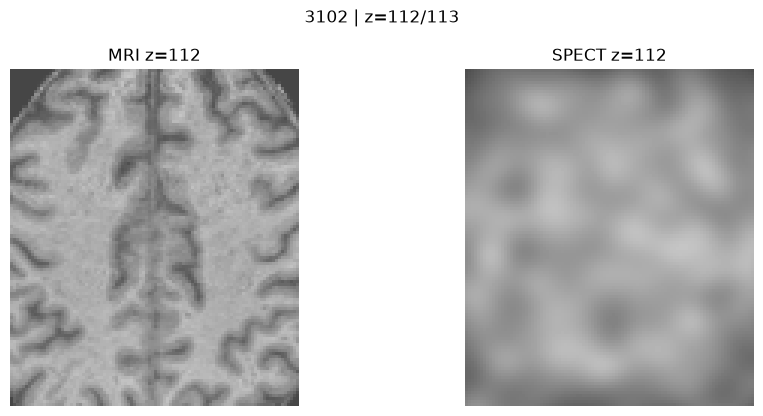

In [11]:
# Fallback SIN widgets (si el slider no aparece / se cuelga otra vez):
# cambia Z_VIEW y re-ejecuta esta celda.
Z_VIEW = 112  # índice nibabel 0-based
FLIP_Z = False

zi = (nz - 1 - Z_VIEW) if FLIP_Z else int(Z_VIEW)
zi = int(np.clip(zi, 0, nz - 1))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].imshow(viz_mri[:, :, zi].T, origin="lower", cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"MRI z={zi}")
axes[0].axis("off")
axes[1].imshow(viz_spect[:, :, zi].T, origin="lower", cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"SPECT z={zi}")
axes[1].axis("off")
fig.suptitle(f"{VIZ_SUBJECT} | z={zi}/{nz-1}", fontsize=12)
fig.tight_layout()
plt.show()


In [12]:
# Anota el rango que viste y ejecuta:
CHOSEN_Z_MIN = 78
CHOSEN_Z_MAX = 112

chosen = slice_indices(CHOSEN_Z_MIN, CHOSEN_Z_MAX, viz_mri.shape, DEFAULT_SLICE_AXIS)
print(f"slice_range = [{CHOSEN_Z_MIN}, {CHOSEN_Z_MAX}]")
print(f"índices efectivos: {chosen[0]}…{chosen[-1]}  (n={len(chosen)})")


slice_range = [78, 112]
índices efectivos: 78…112  (n=35)
